# Comparación final: DT, IQL y líneas base

Lee los CSV que dejan `dt_gpu.ipynb` e `IQL_gpu.ipynb` en `outputs/` y arma las tablas y figuras para el informe. **No reentrena ni evalúa modelos**: sólo consolida resultados.

- `LOGS_LIST` controla qué logs incluir (`random`, `mixto`, `experto`). Los que no existan se saltean.
- Test se muestra sólo si los notebooks ya corrieron con `RUN_TEST=True`.
- Las figuras y tablas se guardan en `outputs/comparacion/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "config_dataset.py").exists():
    raise RuntimeError("Ejecutar el notebook desde 2026/tp")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from protocolo.datos import load_train, make_episodes, split_by_user
from protocolo.metricas import summarize

DATASET = "netflix"
HORIZON = 20
LOGS_LIST = ("random", "mixto")
BASE = Path("outputs")
OUT = BASE / "comparacion"
OUT.mkdir(parents=True, exist_ok=True)

BASELINES = ["random", "popularity", "item_mean", "group_mean", "group_posterior", "sistema_anterior_eps0"]
METRICS = ["normalized", "return", "hit_rate", "ndcg@10", "precision@10"]

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)


def dt_dir(logs):
    return BASE / f"dt_gpu_{logs}"


def iql_dir(logs):
    return BASE / f"iql_gpu_{logs}"


def load_csv(path):
    path = Path(path)
    return pd.read_csv(path) if path.exists() else None


available_logs = [logs for logs in LOGS_LIST if dt_dir(logs).exists() or iql_dir(logs).exists()]
train_all = load_train(DATASET)
train, val = split_by_user(train_all)
train_max = float(make_episodes(train, HORIZON).returns_to_go()[:, 0].max())
print("logs disponibles:", available_logs)
print("máximo retorno de un episodio de train:", train_max)

logs disponibles: ['random']
máximo retorno de un episodio de train: 97.0


In [2]:
def summary_long(df, by):
    s = summarize(df, by=by)
    out = s.index.to_frame(index=False)
    for metric in METRICS:
        out[metric] = s[(metric, "mean")].to_numpy()
    out["ci95"] = s[("normalized", "ci95")].to_numpy()
    return out


def load_validation(logs):
    rows = []
    dt = load_csv(dt_dir(logs) / "comparacion_val.csv")
    base_raw = load_csv(iql_dir(logs) / "iql_baselines_val_sesiones.csv")
    iql_raw = load_csv(iql_dir(logs) / "iql_val_sesiones.csv")

    if base_raw is not None:
        base = summary_long(base_raw, ["policy", "warmup", "group_visible"])
        base = base[base["policy"].isin(BASELINES)]
        rows.append(base)
    elif dt is not None:
        base = dt[dt["policy"].isin(BASELINES)].rename(columns={"visible": "group_visible"})
        rows.append(base)

    if dt is not None:
        dt_rows = dt[dt["policy"].astype(str).str.startswith("dt_")].rename(
            columns={"visible": "group_visible"}
        )
        rows.append(dt_rows)

    if iql_raw is not None:
        iql = summary_long(iql_raw, ["mode", "warmup", "group_visible"])
        iql["policy"] = "iql_" + iql["mode"].astype(str)
        iql = iql.drop(columns="mode")
        rows.append(iql)

    if not rows:
        return None
    out = pd.concat(rows, ignore_index=True)
    for column in ["normalized", "return", "hit_rate", "ndcg@10", "precision@10", "ci95"]:
        if column not in out.columns:
            out[column] = np.nan
    out["logs"] = logs
    return out[["logs", "policy", "warmup", "group_visible", *METRICS, "ci95"]]


frames = [df for df in (load_validation(logs) for logs in available_logs) if df is not None]
validation = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
if len(validation):
    validation.to_csv(OUT / "validacion_larga.csv", index=False)
    print(f"filas de validación: {len(validation)}")
    display(validation.head().round(3))
else:
    print("No hay resultados de validación todavía.")

filas de validación: 36


,logs,policy,warmup,group_visible,normalized,return,hit_rate,ndcg@10,precision@10,ci95
0,random,group_mean,0,False,0.565,80.882,0.754,0.847,0.818,0.014
1,random,group_mean,0,True,0.656,83.467,0.800,0.882,0.858,0.011
2,random,group_mean,5,False,0.580,61.588,0.776,0.843,0.812,0.014
3,random,group_mean,5,True,0.666,63.438,0.821,0.879,0.852,0.012
4,random,group_posterior,0,False,0.617,82.312,0.778,0.848,0.820,0.012


In [3]:
if len(validation):
    for logs in validation["logs"].unique():
        sub = validation[validation["logs"] == logs]
        table = sub.pivot_table(
            index="policy", columns=["warmup", "group_visible"], values="normalized"
        )
        print(f"== {logs} ==")
        display(table.round(3))

    main = validation.pivot_table(
        index=["logs", "policy"], columns=["warmup", "group_visible"], values="normalized"
    )
    main.to_csv(OUT / "validacion_normalizado.csv")
    for metric in ("hit_rate", "ndcg@10"):
        pivot = validation.pivot_table(
            index=["logs", "policy"], columns=["warmup", "group_visible"], values=metric
        )
        pivot.to_csv(OUT / f"validacion_{metric.replace('@', '')}.csv")
        print(metric)
        display(pivot.round(3))
else:
    print("Sin tabla principal.")

== random ==


warmup               0             5       
group_visible    False  True   False  True 
policy                                     
dt_gd0.0_97      0.550  0.588  0.566  0.598
dt_gd0.3_97      0.536  0.561  0.558  0.576
group_mean       0.565  0.656  0.580  0.666
group_posterior  0.617  0.656  0.640  0.666
iql_pi           0.564  0.643  0.587  0.651
iql_q            0.554  0.647  0.584  0.655
item_mean        0.565  0.565  0.580  0.580
popularity      -0.028 -0.028 -0.020 -0.020
random           0.009  0.005 -0.006 -0.005

hit_rate


warmup                      0             5       
group_visible           False  True   False  True 
logs   policy                                     
random dt_gd0.0_97      0.745  0.765  0.767  0.785
       dt_gd0.3_97      0.733  0.749  0.760  0.771
       group_mean       0.754  0.800  0.776  0.821
       group_posterior  0.778  0.800  0.805  0.821
       iql_pi           0.747  0.795  0.774  0.816
       iql_q            0.742  0.796  0.773  0.817
       item_mean        0.754  0.754  0.776  0.776
       popularity       0.452  0.452  0.454  0.454
       random           0.468  0.464  0.459  0.460

ndcg@10


warmup                      0             5       
group_visible           False  True   False  True 
logs   policy                                     
random dt_gd0.0_97      0.817  0.833  0.825  0.843
       dt_gd0.3_97      0.768  0.826  0.804  0.832
       group_mean       0.847  0.882  0.843  0.879
       group_posterior  0.848  0.882  0.853  0.879
       iql_pi           0.841  0.871  0.841  0.874
       iql_q            0.840  0.872  0.841  0.875
       item_mean        0.847  0.847  0.843  0.843
       popularity       0.454  0.454  0.456  0.456
       random           0.470  0.464  0.463  0.467

In [4]:
def load_dispersion(logs):
    rows = []
    dt = load_csv(dt_dir(logs) / "dt_val_barrido.csv")
    dt_comp = load_csv(dt_dir(logs) / "comparacion_val.csv")
    if dt is not None and dt_comp is not None:
        policies = [p for p in dt_comp["policy"].astype(str) if p.startswith("dt_gd0.3_")]
        targets = sorted({int(p.split("_")[-1]) for p in policies})
        if targets:
            target = targets[0]
            sub = dt[(dt["group_dropout"] == 0.3) & (dt["target"] == target)]
            per_seed = sub.groupby(["seed", "warmup", "visible"])["normalized"].mean().reset_index()
            stats = per_seed.groupby(["warmup", "visible"])["normalized"].agg(["mean", "std"]).reset_index()
            stats["policy"] = f"dt_gd0.3_{target}"
            stats["logs"] = logs
            rows.append(stats.rename(columns={"visible": "group_visible"}))

    iql_raw = load_csv(iql_dir(logs) / "iql_val_sesiones.csv")
    if iql_raw is not None:
        per_seed = (
            iql_raw.groupby(["mode", "train_seed", "warmup", "group_visible"])["normalized"]
            .mean().reset_index()
        )
        stats = per_seed.groupby(["mode", "warmup", "group_visible"])["normalized"].agg(
            ["mean", "std"]
        ).reset_index()
        stats["policy"] = "iql_" + stats["mode"].astype(str)
        stats["logs"] = logs
        rows.append(stats.drop(columns="mode"))

    if not rows:
        return None
    return pd.concat(rows, ignore_index=True)[
        ["logs", "policy", "warmup", "group_visible", "mean", "std"]
    ]


frames = [df for df in (load_dispersion(logs) for logs in available_logs) if df is not None]
dispersion = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
if len(dispersion):
    dispersion = dispersion.rename(columns={"mean": "media", "std": "desvio_entre_semillas"})
    dispersion.to_csv(OUT / "dispersion_entre_semillas.csv", index=False)
    display(dispersion.round(3))
else:
    print("Sin datos de dispersión entre semillas.")

,logs,policy,warmup,group_visible,media,desvio_entre_semillas
0,random,dt_gd0.3_97,0,False,0.536,0.008
1,random,dt_gd0.3_97,0,True,0.561,0.009
2,random,dt_gd0.3_97,5,False,0.558,0.005
3,random,dt_gd0.3_97,5,True,0.576,0.008
4,random,iql_pi,0,False,0.564,0.002
5,random,iql_pi,0,True,0.643,0.005
6,random,iql_pi,5,False,0.587,0.001
7,random,iql_pi,5,True,0.651,0.004
8,random,iql_q,0,False,0.554,0.002
9,random,iql_q,0,True,0.647,0.002


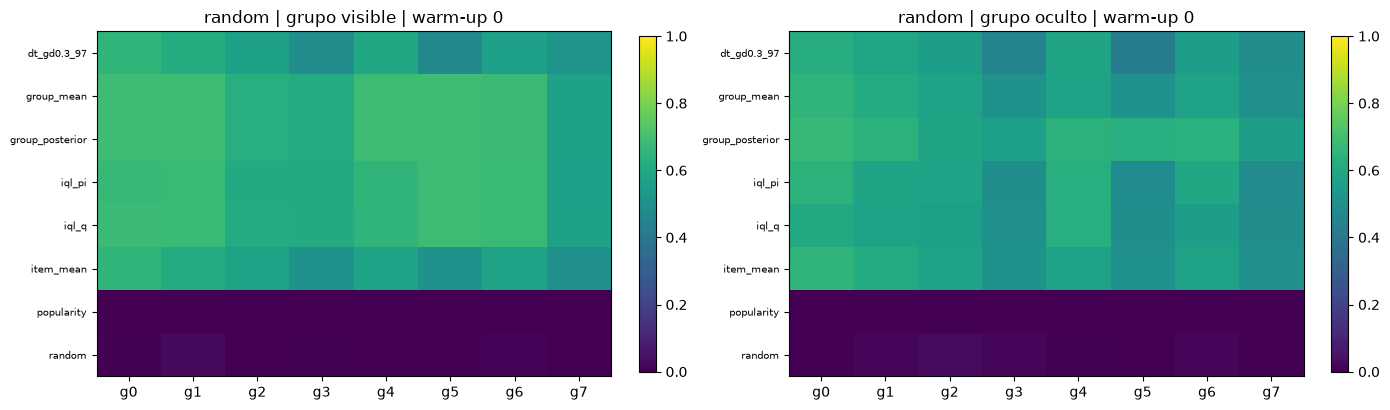

In [5]:
def load_per_group(logs):
    rows = []
    dt = load_csv(dt_dir(logs) / "dt_val_barrido.csv")
    dt_comp = load_csv(dt_dir(logs) / "comparacion_val.csv")
    if dt is not None and dt_comp is not None:
        policies = [p for p in dt_comp["policy"].astype(str) if p.startswith("dt_gd0.3_")]
        targets = sorted({int(p.split("_")[-1]) for p in policies})
        if targets:
            target = targets[0]
            sub = dt[(dt["group_dropout"] == 0.3) & (dt["target"] == target)]
            group_cols = [f"normalized_g{g}" for g in range(8)]
            if all(column in sub.columns for column in group_cols):
                grouped = sub.groupby(["warmup", "visible"])[group_cols].mean().reset_index()
                melted = grouped.melt(
                    id_vars=["warmup", "visible"], value_vars=group_cols,
                    var_name="group", value_name="normalized",
                )
                melted["group"] = melted["group"].str.replace("normalized_g", "", regex=False).astype(int)
                melted["policy"] = f"dt_gd0.3_{target}"
                melted["logs"] = logs
                rows.append(melted.rename(columns={"visible": "group_visible"}))

    iql_raw = load_csv(iql_dir(logs) / "iql_val_sesiones.csv")
    if iql_raw is not None:
        s = summarize(iql_raw, by=["mode", "warmup", "group_visible", "group"])
        out = s.index.to_frame(index=False)
        out["normalized"] = s[("normalized", "mean")].to_numpy()
        out["policy"] = "iql_" + out["mode"].astype(str)
        out = out.drop(columns="mode")
        out["logs"] = logs
        rows.append(out)

    base_raw = load_csv(iql_dir(logs) / "iql_baselines_val_sesiones.csv")
    if base_raw is not None:
        s = summarize(base_raw, by=["policy", "warmup", "group_visible", "group"])
        out = s.index.to_frame(index=False)
        out["normalized"] = s[("normalized", "mean")].to_numpy()
        out = out[out["policy"].isin(BASELINES)]
        out["logs"] = logs
        rows.append(out)

    if not rows:
        return None
    return pd.concat(rows, ignore_index=True)[
        ["logs", "policy", "warmup", "group_visible", "group", "normalized"]
    ]


frames = [df for df in (load_per_group(logs) for logs in available_logs) if df is not None]
per_group = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
if len(per_group):
    per_group.to_csv(OUT / "validacion_por_grupo.csv", index=False)
    for logs in per_group["logs"].unique():
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
        for ax, visible in zip(axes, (True, False)):
            table = per_group[
                (per_group["logs"] == logs)
                & (per_group["warmup"] == 0)
                & (per_group["group_visible"] == visible)
            ].pivot_table(index="policy", columns="group", values="normalized")
            if table.empty:
                ax.axis("off")
                continue
            image = ax.imshow(table.values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
            ax.set_yticks(range(len(table.index)), table.index, fontsize=7)
            ax.set_xticks(range(len(table.columns)), [f"g{g}" for g in table.columns])
            ax.set_title(f"{logs} | grupo {'visible' if visible else 'oculto'} | warm-up 0")
            fig.colorbar(image, ax=ax, fraction=0.03)
        plt.tight_layout()
        plt.savefig(OUT / f"por_grupo_{logs}.png", dpi=150)
        plt.show()
else:
    print("Sin resultados por grupo.")

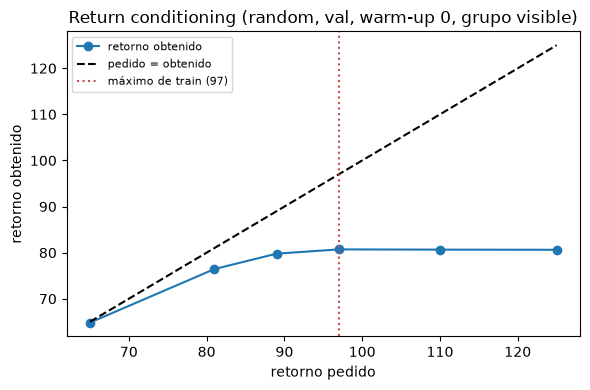

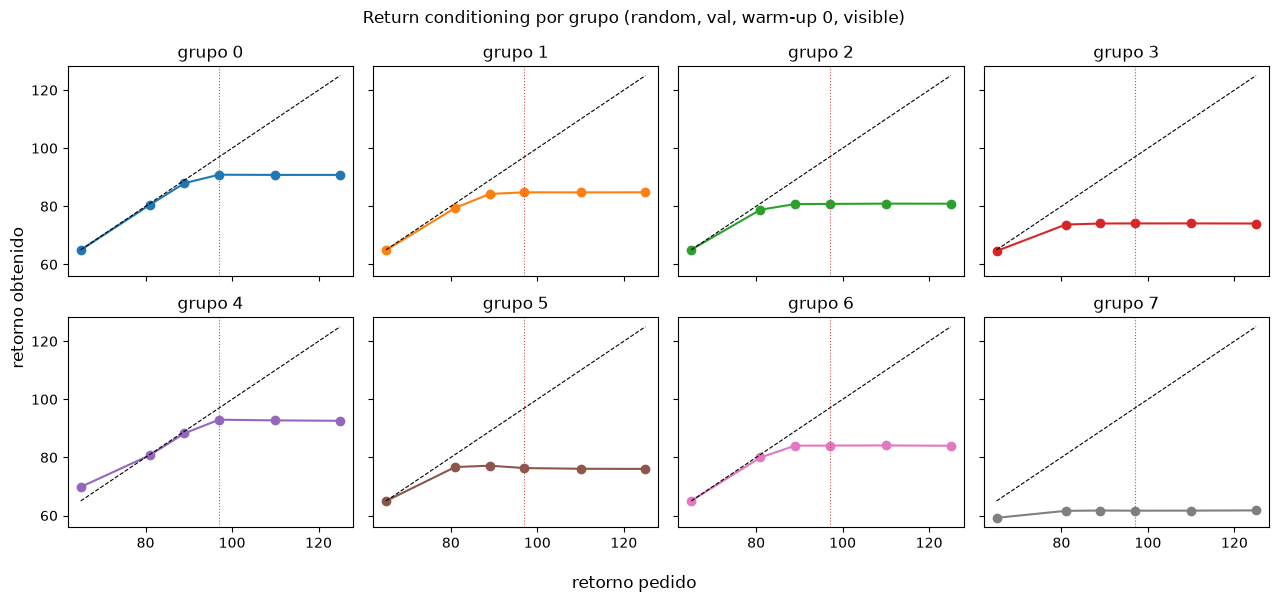

In [6]:
def plot_return_conditioning(logs):
    dt = load_csv(dt_dir(logs) / "dt_val_barrido.csv")
    if dt is None:
        return
    sub = dt[(dt["group_dropout"] == 0.3) & (dt["warmup"] == 0) & (dt["visible"])]
    if sub.empty:
        return
    mean_return = sub.groupby("target")["return"].mean()
    group_cols = [f"return_g{g}" for g in range(8)]
    group_returns = sub.groupby("target")[group_cols].mean()
    axis_max = max(mean_return.index.max(), train_max)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(mean_return.index, mean_return.values, "o-", label="retorno obtenido")
    ax.plot([mean_return.index.min(), axis_max], [mean_return.index.min(), axis_max], "k--", label="pedido = obtenido")
    ax.axvline(train_max, color="#c44e52", ls=":", label=f"máximo de train ({train_max:.0f})")
    ax.set_xlabel("retorno pedido")
    ax.set_ylabel("retorno obtenido")
    ax.set_title(f"Return conditioning ({logs}, val, warm-up 0, grupo visible)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(OUT / f"return_conditioning_{logs}.png", dpi=150)
    plt.show()

    fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
    for group, ax in enumerate(axes.ravel()):
        ax.plot(group_returns.index, group_returns[f"return_g{group}"], "o-", color=f"C{group}")
        ax.plot([group_returns.index.min(), axis_max], [group_returns.index.min(), axis_max], "k--", lw=0.8)
        ax.axvline(train_max, color="#c44e52", ls=":", lw=0.8)
        ax.set_title(f"grupo {group}")
    fig.supxlabel("retorno pedido")
    fig.supylabel("retorno obtenido")
    fig.suptitle(f"Return conditioning por grupo ({logs}, val, warm-up 0, visible)")
    plt.tight_layout()
    plt.savefig(OUT / f"return_conditioning_por_grupo_{logs}.png", dpi=150)
    plt.show()


for logs in available_logs:
    plot_return_conditioning(logs)

In [7]:
if len(validation):
    focus = [p for p in validation["policy"].unique() if p.startswith(("dt_", "iql_"))]
    policies = [p for p in BASELINES + focus if p in set(validation["policy"])]
    table = validation[validation["policy"].isin(policies)].pivot_table(
        index="policy", columns=["logs", "warmup", "group_visible"], values="normalized"
    )
    table.to_csv(OUT / "calidad_logs.csv")
    print("Comparación entre logs (normalizado):")
    display(table.round(3))
    if validation["logs"].nunique() > 1:
        print("Cambio de las líneas base entre logs (mixto − random):")
        base = validation[validation["policy"].isin(BASELINES)].pivot_table(
            index="policy", columns=["logs", "warmup", "group_visible"], values="normalized"
        )
        if "random" in validation["logs"].unique() and "mixto" in validation["logs"].unique():
            delta = pd.DataFrame(index=base.index)
            for column in [c for c in base.columns if c[0] == "mixto"]:
                random_column = ("random", *column[1:])
                if random_column in base.columns:
                    delta[column] = base[column] - base[random_column]
            display(delta.round(3))
    else:
        print("Sólo hay un tipo de logs; correr mixto para comparar.")
else:
    print("Sin resultados para comparar logs.")

Comparación entre logs (normalizado):


logs            random                     
warmup               0             5       
group_visible    False  True   False  True 
policy                                     
dt_gd0.0_97      0.550  0.588  0.566  0.598
dt_gd0.3_97      0.536  0.561  0.558  0.576
group_mean       0.565  0.656  0.580  0.666
group_posterior  0.617  0.656  0.640  0.666
iql_pi           0.564  0.643  0.587  0.651
iql_q            0.554  0.647  0.584  0.655
item_mean        0.565  0.565  0.580  0.580
popularity      -0.028 -0.028 -0.020 -0.020
random           0.009  0.005 -0.006 -0.005

Sólo hay un tipo de logs; correr mixto para comparar.


In [8]:
for logs in available_logs:
    print(f"=== {logs} ===")
    dt_hpo = load_csv(dt_dir(logs) / "hpo_resultados.csv")
    if dt_hpo is not None:
        columns = [c for c in ["d_model", "n_heads", "n_layers", "dropout", "lr", "batch_size", "epochs", "target", "score", "val_ce"] if c in dt_hpo.columns]
        print("DT HPO (top 3):")
        display(dt_hpo.sort_values("score", ascending=False).head(3)[columns].round(3))
    iql_hpo = load_csv(iql_dir(logs) / "hpo_resultados.csv")
    if iql_hpo is not None:
        columns = [c for c in ["d_model", "n_heads", "n_layers", "dropout", "lr", "batch_size", "epochs", "tau", "beta", "gamma", "score", "score_robusto"] if c in iql_hpo.columns]
        print("IQL HPO (top 3):")
        display(iql_hpo.sort_values("score_robusto", ascending=False).head(3)[columns].round(3))
    grid = load_csv(iql_dir(logs) / "grid_iql.csv")
    if grid is not None:
        print("IQL grilla τ, β, γ:")
        display(grid.round(3))
        gamma = grid.groupby("gamma")[["pi", "q", "score", "score_robusto"]].mean()
        gamma.to_csv(OUT / f"grid_gamma_{logs}.csv")
        print("γ=0 frente a γ>0:")
        display(gamma.round(3))

=== random ===
DT HPO (top 3):


,d_model,n_heads,n_layers,dropout,lr,batch_size,epochs,target,score,val_ce
0,128,4,3,0.2,0.001,1024,40,97.0,0.570,6.580
1,128,8,3,0.0,0.000,1024,20,97.0,0.561,6.587
2,128,8,2,0.0,0.001,1024,40,97.0,0.559,6.588


IQL HPO (top 3):


,d_model,n_heads,n_layers,dropout,lr,batch_size,epochs,tau,beta,gamma,score,score_robusto
0,128,4,2,0.0,0.001,512,10,0.9,3.0,0.9,0.595,0.591
1,128,8,2,0.1,0.000,256,10,0.9,3.0,0.9,0.588,0.588
2,64,4,3,0.0,0.001,1024,10,0.9,3.0,0.9,0.577,0.570


IQL grilla τ, β, γ:


,tau,beta,gamma,pi,q,score,score_robusto,val_pi,minutos
0,0.7,3.0,0.9,0.602,0.599,0.600,0.599,7.637,0.588
1,0.7,10.0,0.9,0.597,0.601,0.599,0.597,56.597,0.590
2,0.9,3.0,0.9,0.599,0.591,0.595,0.591,4.572,0.606
3,0.7,10.0,0.0,0.590,0.610,0.600,0.590,49.837,0.599
4,0.7,3.0,0.0,0.590,0.609,0.600,0.590,7.313,0.561
5,0.9,3.0,0.0,0.589,0.608,0.598,0.589,4.307,0.601
6,0.9,10.0,0.9,0.586,0.596,0.591,0.586,15.257,0.601
7,0.9,10.0,0.0,0.584,0.608,0.596,0.584,12.098,0.600


γ=0 frente a γ>0:


,pi,q,score,score_robusto
gamma,,,,
0.0,0.588,0.609,0.599,0.588
0.9,0.596,0.597,0.596,0.593


In [9]:
def load_test(logs):
    frames = []
    for directory in (dt_dir(logs), iql_dir(logs)):
        path = directory / "eval" / "test" / "sesiones.csv"
        if not path.exists():
            continue
        df = pd.read_csv(path)
        df["policy"] = df["policy"].astype(str).str.replace(
            r"dt_seed\d+", "dt", regex=True
        ).str.replace(r"iql_(pi|q)_seed\d+", r"iql_\1", regex=True)
        s = summarize(df, by=["policy", "warmup", "group_visible"])
        out = s.index.to_frame(index=False)
        for metric in METRICS:
            out[metric] = s[(metric, "mean")].to_numpy()
        out["ci95"] = s[("normalized", "ci95")].to_numpy()
        out["logs"] = logs
        frames.append(out)
    if not frames:
        return None
    return pd.concat(frames, ignore_index=True)


frames = [df for df in (load_test(logs) for logs in available_logs) if df is not None]
test_table = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
if len(test_table):
    test_table.to_csv(OUT / "test_largo.csv", index=False)
    for logs in test_table["logs"].unique():
        table = test_table[test_table["logs"] == logs].pivot_table(
            index="policy", columns=["warmup", "group_visible"], values="normalized"
        )
        print(f"== TEST {logs} ==")
        display(table.round(3))
else:
    print("Test pendiente: correr los notebooks con RUN_TEST=True una sola vez al final.")

Test pendiente: correr los notebooks con RUN_TEST=True una sola vez al final.


## Cómo leer y qué falta

- **Tabla principal:** `validacion_normalizado.csv`; métricas secundarias en `validacion_hit_rate.csv` y `validacion_ndcg10.csv`.
- **Dispersión:** `dispersion_entre_semillas.csv` (media y desvío entre semillas de entrenamiento). El IC 95 % por usuario está en la tabla principal (`ci95`); no mezclar ambos.
- **Per-group:** `validacion_por_grupo.csv` y las figuras `por_grupo_<logs>.png`.
- **Return conditioning:** `return_conditioning_<logs>.png` y `return_conditioning_por_grupo_<logs>.png` (pedido vs obtenido; más allá del máximo de train es extrapolación).
- **Calidad de logs:** `calidad_logs.csv`; `popularity` debería subir fuerte con `mixto`, `item_mean` empeorar por sesgo de selección y `group_mean` mantenerse.
- **Test:** `test_largo.csv` sólo si los notebooks se corrieron con `RUN_TEST=True` una vez al final.

Antes de la entrega: verificar que la configuración y el retorno se eligieron en validación, que no se reportó la mejor semilla, y que las conclusiones se apoyan en el protocolo y no en las pérdidas.